# 09. Error analysis: where does the model go wrong?

AUC is one number for the whole population. Error analysis asks *which applicants* the model gets wrong and whether the errors have a pattern we can act on.

**Method**
1. Get an honest prediction for every applicant: **out-of-fold** predictions (each applicant is predicted by a model that never saw them).
2. Check ranking quality and calibration overall.
3. Pick an operating threshold and look at the two kinds of mistake: *missed defaulters* (false negatives) and *wrongly flagged good applicants* (false positives).
4. Compare segments (gender, age, income, data availability) for weaker spots.
5. Profile the missed defaulters against the caught ones.

In [1]:
# Build the feature table and produce out-of-fold predictions with the tuned model
import sys, json
# make the project's src/ package importable from the notebooks folder
sys.path.append("..")

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import calibration_curve

from src.features import clean, add_features

df = pd.read_csv("../data/raw/HC_application_train.csv")
# reset_index keeps row positions aligned with X
y = df["TARGET"].reset_index(drop=True)
# same feature table as in notebooks 06 and 07
X = add_features(clean(df.drop(columns="TARGET")))
# attach the pre-computed aggregate tables
for name in ["bureau", "previous", "installments"]:
    X = X.join(pd.read_pickle(f"../data/processed/{name}.pkl"), on="SK_ID_CURR")
X = X.drop(columns="SK_ID_CURR").reset_index(drop=True)
# text columns become LightGBM native categories
for c in X.select_dtypes(include=["object", "string"]):
    X[c] = X[c].astype("category")

# tuned settings saved by notebook 06
params = json.load(open("../models/best_params.json"))
# one slot per applicant, filled by the fold that did not train on them
oof = np.zeros(len(X))
# 5 stratified folds (seed 7)
for tr, va in StratifiedKFold(5, shuffle=True, random_state=7).split(X, y):
    # train on 4 folds
    m = lgb.LGBMClassifier(**params, random_state=42, verbose=-1).fit(X.iloc[tr], y.iloc[tr])
    # predict the held-out fold only
    oof[va] = m.predict_proba(X.iloc[va])[:, 1]

print("out-of-fold AUC:", round(roc_auc_score(y, oof), 4))
# one table with features, truth and score for the analysis below
res = X.assign(TARGET=y, score=oof)

out-of-fold AUC: 0.7912


/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_80558/1553469350.py:31: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  res = X.assign(TARGET=y, score=oof)


**Insight:** the out-of-fold AUC is 0.7912 over all 307,511 applicants, matching the tuned cross-validation result from notebook 06 within noise. The PerformanceWarning is a pandas efficiency notice and does not affect the results.

## 1. Does a higher score really mean higher risk? (lift by decile)
Sort applicants by score, cut into ten equal groups, and compare the actual default rate in each. A good ranking gives a steep staircase.

In [2]:
# Cut applicants into 10 equal score groups and compare predicted and actual default rates
# rank first so ties cannot break the equal-size groups
res["decile"] = pd.qcut(res["score"].rank(method="first"), 10, labels=range(1, 11))
# size, actual rate and average score per decile
lift = res.groupby("decile", observed=True).agg(applicants=("TARGET", "size"), default_rate=("TARGET", "mean"), mean_score=("score", "mean"))
# what fraction of all defaulters falls in each decile
lift["share_of_all_defaults"] = res.groupby("decile", observed=True)["TARGET"].sum() / y.sum()
# decile rate divided by the overall default rate
lift["lift_vs_average"] = lift["default_rate"] / y.mean()
lift.round(3)

/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_80558/2833700358.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  res["decile"] = pd.qcut(res["score"].rank(method="first"), 10, labels=range(1, 11))


,applicants,default_rate,mean_score,share_of_all_defaults,lift_vs_average
decile,,,,,
1,30752,0.008,0.009,0.009,0.094
2,30751,0.014,0.016,0.018,0.179
3,30751,0.022,0.023,0.027,0.270
4,30751,0.030,0.030,0.038,0.376
5,30751,0.039,0.040,0.048,0.484
6,30751,0.052,0.053,0.064,0.643
7,30751,0.074,0.071,0.092,0.920
8,30751,0.106,0.099,0.132,1.319
9,30751,0.155,0.151,0.192,1.922


**Insight:** the actual default rate rises at every step from decile 1 to 10, with no reversals, and the average score tracks it closely in every decile (for example 0.309 against 0.306 in decile 10). The model's ranking is consistent across the whole range, not only at the top.

The left plot shows the table above as bars against the overall default rate. The right plot is a calibration curve: if predicted probabilities are honest, the points sit on the diagonal.

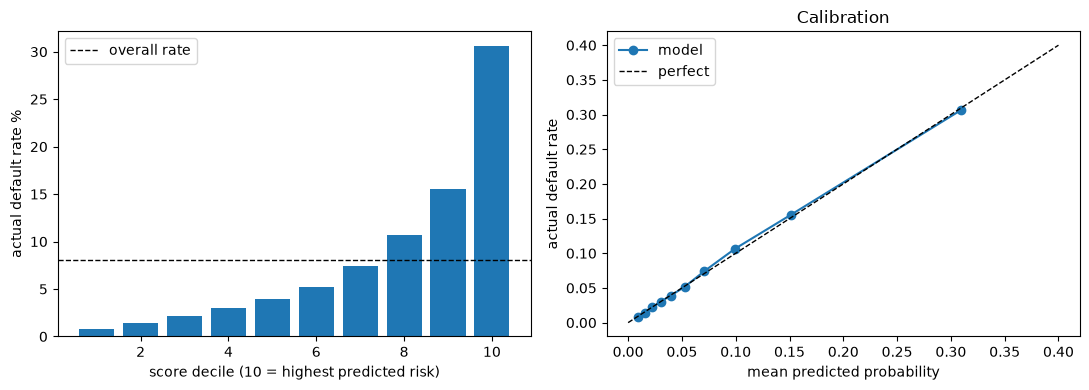

In [3]:
# Plot lift by decile and the calibration curve, and save the figure
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# actual default rate per score decile, in percent
ax[0].bar(lift.index.astype(int), lift["default_rate"] * 100)
# dashed line = overall default rate
ax[0].axhline(y.mean() * 100, color="k", ls="--", lw=1, label="overall rate")
ax[0].set_xlabel("score decile (10 = highest predicted risk)"); ax[0].set_ylabel("actual default rate %"); ax[0].legend()

# 10 equal-size bins by predicted probability
frac_pos, mean_pred = calibration_curve(y, oof, n_bins=10, strategy="quantile")
# diagonal = perfect calibration
ax[1].plot(mean_pred, frac_pos, "o-", label="model"); ax[1].plot([0, 0.4], [0, 0.4], "k--", lw=1, label="perfect")
ax[1].set_xlabel("mean predicted probability"); ax[1].set_ylabel("actual default rate"); ax[1].set_title("Calibration"); ax[1].legend()
plt.tight_layout(); plt.savefig("../assets/error_lift_calibration.png", dpi=150); plt.show()

**Insight:** the bars show the same steep rise, with decile 10 well above the overall rate line. The calibration points lie on or very close to the diagonal, slightly above it in the middle deciles (for example 0.106 actual against 0.099 predicted in decile 8), so predicted probabilities are close to observed rates.

## 2. Operating threshold and the two kinds of mistake
A lender must pick a cut-off. The table shows what each choice costs. The cost ratio below is an **illustrative assumption** (a missed defaulter costs 5x a wrongly rejected good applicant), not a Home Credit figure; change it to see how the best threshold moves.

In [4]:
# Flag the riskiest 5% to 40% of applicants and count what each choice costs
# relative cost of a missed defaulter vs a wrongly rejected applicant
COST_FN, COST_FP = 5, 1          # assumption, edit freely
rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.40]:
    # score cut-off that flags the top `share` of applicants
    thr = np.quantile(oof, 1 - share)
    # predicted positive
    flag = oof >= thr
    # tp = caught defaulters, fp = good applicants flagged, fn = defaulters missed
    tp = (flag & (y == 1)).sum(); fp = (flag & (y == 0)).sum(); fn = (~flag & (y == 1)).sum()
    # precision = share of flagged applicants that really default
    rows.append({"flag riskiest %": int(share * 100), "threshold": round(thr, 3),
                 "defaulters caught %": round(100 * tp / y.sum(), 1),
                 "precision %": round(100 * tp / flag.sum(), 1),
                 "good applicants flagged": int(fp), "defaulters missed": int(fn),
                 "illustrative cost": COST_FN * fn + COST_FP * fp})
pd.DataFrame(rows)

,flag riskiest %,threshold,defaulters caught %,precision %,good applicants flagged,defaulters missed,illustrative cost
0,5,0.276,23.5,37.9,9544,18993,104509
1,10,0.193,37.9,30.6,21336,15409,98381
2,20,0.119,57.1,23.1,47316,10638,100506
3,30,0.083,70.3,18.9,74794,7365,111619
4,40,0.061,79.5,16.1,103261,5081,128666


**Insight:** flagging more applicants catches more defaulters but precision falls, from 23.5% caught at 37.9% precision (top 5%) to 79.5% caught at 16.1% precision (top 40%). Under the assumed 5:1 cost ratio the cost is lowest at the 10% cut-off (98,381), but it is nearly flat from 10% to 20%, so the cost assumption drives the choice.

## 3. Segments: where is the model weaker?
For each group: size, actual default rate, average predicted probability (a big gap means miscalibration for that group) and AUC inside the group (how well it ranks people *within* it).

In [5]:
# Build a table of size, default rate, predicted rate and within-group AUC for each segment
# age in years from the negative day count
age = -res["DAYS_BIRTH"] / 365
# each entry maps every applicant to a group label
segments = {
    "gender": res["CODE_GENDER"].astype(object).fillna("missing"),
    "age band": pd.cut(age, [20, 30, 40, 50, 60, 70]).astype(str),
    "income quintile": pd.qcut(res["AMT_INCOME_TOTAL"], 5, labels=["Q1 low", "Q2", "Q3", "Q4", "Q5 high"]).astype(str),
    "contract type": res["NAME_CONTRACT_TYPE"].astype(object),
    "education": res["NAME_EDUCATION_TYPE"].astype(object),
    # missing aggregate count means no record in that table
    "has bureau record": np.where(res["BUREAU_COUNT"].notna(), "yes", "no"),
    "has previous application": np.where(res["PREV_COUNT"].notna(), "yes", "no"),
    "employment placeholder (pensioner-like)": np.where(res["DAYS_EMPLOYED_ANOM"] == 1, "yes", "no"),
    "EXT_SOURCE_1 missing": np.where(res["EXT_SOURCE_1"].isna(), "yes", "no"),
    "EXT_SOURCE_3 missing": np.where(res["EXT_SOURCE_3"].isna(), "yes", "no"),
}
# evaluate each group separately
out = []
for seg, labels in segments.items():
    for g in pd.unique(labels):
        mask = (labels == g)
        # skip tiny groups and groups with only one class (AUC undefined)
        if mask.sum() < 500 or res.loc[mask, "TARGET"].nunique() < 2:
            continue
        # AUC inside group = how well the score ranks people within the group
        out.append({"segment": seg, "group": g, "n": int(mask.sum()),
                    "default rate %": round(100 * res.loc[mask, "TARGET"].mean(), 2),
                    "mean predicted %": round(100 * res.loc[mask, "score"].mean(), 2),
                    "AUC inside group": round(roc_auc_score(res.loc[mask, "TARGET"], res.loc[mask, "score"]), 3)})
# 28 groups in total
seg_table = pd.DataFrame(out)
seg_table

,segment,group,n,default rate %,mean predicted %,AUC inside group
0,gender,M,105059,10.14,9.94,0.782
1,gender,F,202448,7.00,7.00,0.791
2,age band,"(20, 30]",45021,11.46,11.50,0.767
3,age band,"(40, 50]",76541,7.65,7.58,0.796
4,age band,"(50, 60]",68062,6.13,6.14,0.783
5,age band,"(30, 40]",82308,9.58,9.40,0.790
6,age band,"(60, 70]",35579,4.92,4.83,0.752
7,income quintile,Q4,75513,8.06,7.87,0.787
8,income quintile,Q5 high,47118,6.52,6.54,0.796
9,income quintile,Q1 low,63671,8.21,8.22,0.792


**Insight:** the within-group AUC ranges from 0.752 to 0.802 against 0.7912 overall, and in every group the predicted rate is within about 0.5 percentage points of the actual rate. The groups overlap (for example pensioner-like applicants are probably older), so the weak spots are likely related rather than independent.

Sort the same table to pull out the groups with the weakest ranking and the largest gap between predicted and actual rate.

In [6]:
# Show the weakest-ranked segments and the largest calibration gaps
# negative = the model under-predicts that group's default rate
seg_table["calibration gap (pp)"] = (seg_table["mean predicted %"] - seg_table["default rate %"]).round(2)
print("Weakest ranking (lowest AUC inside group):")
# lowest AUC first
display(seg_table.sort_values("AUC inside group").head(6))
print("Largest calibration gaps:")
# sort by the absolute size of the gap
display(seg_table.reindex(seg_table["calibration gap (pp)"].abs().sort_values(ascending=False).index).head(6))

Weakest ranking (lowest AUC inside group):


,segment,group,n,default rate %,mean predicted %,AUC inside group,calibration gap (pp)
6,age band,"(60, 70]",35579,4.92,4.83,0.752,-0.09
23,employment placeholder (pensioner-like),yes,55374,5.40,5.35,0.766,-0.05
2,age band,"(20, 30]",45021,11.46,11.50,0.767,0.04
17,education,Lower secondary,3816,10.93,10.39,0.772,-0.54
19,has bureau record,no,44020,10.12,10.04,0.779,-0.08
16,education,Incomplete higher,10277,8.48,8.38,0.780,-0.10


Largest calibration gaps:


,segment,group,n,default rate %,mean predicted %,AUC inside group,calibration gap (pp)
17,education,Lower secondary,3816,10.93,10.39,0.772,-0.54
0,gender,M,105059,10.14,9.94,0.782,-0.20
7,income quintile,Q4,75513,8.06,7.87,0.787,-0.19
5,age band,"(30, 40]",82308,9.58,9.40,0.790,-0.18
11,income quintile,Q3,35453,8.68,8.50,0.787,-0.18
26,EXT_SOURCE_3 missing,no,246546,7.77,7.67,0.793,-0.10


**Insight:** the weakest ranking is age 60 to 70 (AUC 0.752) and the employment-placeholder group (0.766). The largest calibration gap is lower secondary education at -0.54 percentage points (3,816 people, so noisy); all other gaps are 0.20 or smaller. No confidence intervals were computed, so small differences between groups should not be over-read.

## 4. Profile of missed defaulters
Flag the riskiest 20% as the example threshold. Compare defaulters the model **caught** with defaulters it **missed** (scored low), and also with the good applicants it **wrongly flagged**. The columns are medians; the last column shows how far apart caught and missed defaulters are in standard-deviation units.

In [7]:
# Split applicants at the 20% cut-off into four groups and compare their median profile
# score above which the riskiest 20% are flagged
thr = np.quantile(oof, 0.80)
# caught / missed defaulters, wrongly flagged good applicants, and everyone else
res["group"] = np.select([(res.TARGET == 1) & (res.score >= thr), (res.TARGET == 1) & (res.score < thr),
                          (res.TARGET == 0) & (res.score >= thr)],
                         ["caught defaulter", "missed defaulter", "wrongly flagged"], default="correctly cleared")
# size of each group
print(res["group"].value_counts().to_string())

# features to compare
cols = ["EXT_SOURCE_MEAN", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "AGE_YEARS", "YEARS_EMPLOYED",
        "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO",
        "INST_DAYS_LATE_max", "PREV_COUNT", "BUREAU_COUNT"]
# median of each feature per group, features as rows
prof = res.groupby("group")[cols].median().T
# overall standard deviation, used to scale the gap
sd = res[cols].std()
# gap between caught and missed medians, in standard deviations
prof["gap caught vs missed (SD)"] = ((prof["caught defaulter"] - prof["missed defaulter"]) / sd).round(2)
prof.round(3)

group
correctly cleared    235370
wrongly flagged       47316
caught defaulter      14187
missed defaulter      10638


/var/folders/42/t3x7l9v110s8dwq65my59j540000gn/T/ipykernel_80558/3991694107.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  res["group"] = np.select([(res.TARGET == 1) & (res.score >= thr), (res.TARGET == 1) & (res.score < thr),


group,caught defaulter,correctly cleared,missed defaulter,wrongly flagged,gap caught vs missed (SD)
EXT_SOURCE_MEAN,0.319,0.562,0.506,0.353,-1.25
EXT_SOURCE_1,0.277,0.554,0.471,0.304,-0.92
EXT_SOURCE_2,0.331,0.597,0.549,0.382,-1.14
EXT_SOURCE_3,0.276,0.580,0.515,0.317,-1.23
AGE_YEARS,36.907,44.753,42.597,37.367,-0.48
YEARS_EMPLOYED,2.896,5.151,4.319,3.068,-0.22
AMT_INCOME_TOTAL,135000.000,157500.000,144427.500,135000.000,-0.04
AMT_CREDIT,469152.000,521280.000,521280.000,481176.000,-0.13
AMT_ANNUITY,25407.000,24813.000,24966.000,25078.500,0.03
CREDIT_INCOME_RATIO,3.176,3.288,3.333,3.198,-0.06


**Insight:** at the 20% cut-off 14,187 defaulters are caught and 10,638 missed. The caught-versus-missed gap is largest for the external scores (-1.25 SD for `EXT_SOURCE_MEAN`, -1.23 for `EXT_SOURCE_3`), while amount, ratio and count features differ by 0.23 SD or less.

Medians hide category effects, so this step compares how the four groups are distributed across a few categorical features (column percentages, so each column sums to 100).

In [8]:
# Compare category shares across the four groups, top 5 categories per feature
# categorical features to profile
cats = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "NAME_CONTRACT_TYPE", "CODE_GENDER"]
for c in cats:
    # column percentages: share of each group in each category
    t = pd.crosstab(res[c].astype(object).fillna("missing"), res["group"], normalize="columns").mul(100).round(1)
    print(c); display(t[["caught defaulter", "missed defaulter", "wrongly flagged", "correctly cleared"]].sort_values("missed defaulter", ascending=False).head(5))

NAME_INCOME_TYPE


group,caught defaulter,missed defaulter,wrongly flagged,correctly cleared
NAME_INCOME_TYPE,,,,
Working,67.7,52.9,64.9,48.0
Commercial associate,20.5,23.1,21.6,23.8
Pensioner,7.9,17.5,9.0,20.4
State servant,3.9,6.5,4.5,7.8
Businessman,0.0,0.0,0.0,0.0


NAME_EDUCATION_TYPE

group,caught defaulter,missed defaulter,wrongly flagged,correctly cleared
NAME_EDUCATION_TYPE,,,,
Secondary / secondary special,82.9,73.0,81.2,68.2
Higher education,11.8,22.0,13.4,27.4
Incomplete higher,3.4,3.6,3.6,3.3
Lower secondary,1.9,1.4,1.8,1.1
Academic degree,0.0,0.0,0.0,0.1


OCCUPATION_TYPE


group,caught defaulter,missed defaulter,wrongly flagged,correctly cleared
OCCUPATION_TYPE,,,,
missing,21.0,30.9,22.3,33.8
Laborers,27.5,18.2,25.8,15.8
Sales staff,13.3,11.4,13.5,9.6
Core staff,6.0,8.3,6.3,9.7
Drivers,9.7,6.8,9.7,5.1


NAME_CONTRACT_TYPE


group,caught defaulter,missed defaulter,wrongly flagged,correctly cleared
NAME_CONTRACT_TYPE,,,,
Cash loans,95.5,91.0,94.4,89.4
Revolving loans,4.5,9.0,5.6,10.6


CODE_GENDER


group,caught defaulter,missed defaulter,wrongly flagged,correctly cleared
CODE_GENDER,,,,
F,52.3,63.5,53.8,69.2
M,47.7,36.5,46.2,30.8
missing,0.0,0.0,0.0,0.0


**Insight:** these are shares within each group, not default rates. Missed defaulters have more applicants with a missing `OCCUPATION_TYPE` (30.9% against 21.0% for caught) and more revolving loans (9.0% against 4.5%), again resembling the correctly cleared group.

## 5. Why does the model miss them? SHAP for a few missed defaulters
For the most confidently wrong cases, which features pulled the score down?

In [9]:
# Explain the 300 lowest-scored defaulters with SHAP to see what pulled their scores down
# imported here because it is only needed for this step
import shap
# model refit on all data, only used for explanation (its own training rows are explained)
final = lgb.LGBMClassifier(**params, random_state=42, verbose=-1).fit(X, y)
# index of the 300 defaulters with the lowest out-of-fold score
worst = res[res.TARGET == 1].nsmallest(300, "score").index
# SHAP values for those applicants
sv = shap.TreeExplainer(final).shap_values(X.loc[worst])
# some versions return one array per class
sv = sv[1] if isinstance(sv, list) else sv
# average SHAP per feature, most negative first
mean_push = pd.Series(sv.mean(axis=0), index=X.columns).sort_values()
print("Average SHAP of the 300 lowest-scored defaulters (negative = pushed the score down, i.e. towards 'safe'):")
mean_push.head(12).round(3)

Average SHAP of the 300 lowest-scored defaulters (negative = pushed the score down, i.e. towards 'safe'):


/Users/dhanyarajendran/Desktop/NeueFische/myproject/Home-Credit-Default-Risk/.venv/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


EXT_SOURCE_MEAN                      -0.269
EXT_SOURCE_MIN                       -0.092
EXT_SOURCE_2                         -0.074
EXT_SOURCE_3                         -0.069
CODE_GENDER                          -0.050
EXT_SOURCE_PROD                      -0.047
ANNUITY_CREDIT_RATIO                 -0.038
CREDIT_GOODS_RATIO                   -0.036
INST_DAYS_LATE_max                   -0.028
INST_AMT_PAYMENT_sum                 -0.025
DAYS_EMPLOYED                        -0.022
PREV_DAYS_LAST_DUE_1ST_VERSION_max   -0.021
dtype: float64

**Insight:** `EXT_SOURCE_MEAN` pulled these scores down by far the most (-0.269), and external-score features take five of the top six places (MEAN, MIN, 2, 3, PROD). Note the SHAP model was trained on all rows, including these applicants, so the numbers are indicative rather than strictly out-of-sample.

Save the out-of-fold scores and group labels so later notebooks can reuse them without retraining.

In [10]:
# Save out-of-fold predictions for reuse
# create the output folder if missing
Path("../models").mkdir(exist_ok=True)
res[["TARGET", "score", "group"]].to_pickle("../models/oof_predictions.pkl")
print("saved out-of-fold predictions")

saved out-of-fold predictions


## Findings
- **Ranking is good and consistent.** Out-of-fold AUC 0.7912. Default rate climbs steadily from 0.8% in the lowest score decile to 30.6% in the highest (3.8x the average); the top decile holds 37.9% of all defaulters.
- **Calibration is good.** Mean predicted probability matches the actual rate in every decile (top decile 30.9% vs 30.6%) and within about 0.5 percentage points in every segment checked, so the scores can be read as probabilities.
- **Weaker spots (ranking inside the group):** age 60 to 70 (AUC 0.752), pensioner-like applicants with the employment placeholder (0.766), age 20 to 30 (0.767), lower secondary education (0.772, only 3,816 people) and applicants without a bureau record (0.779). The best group is applicants with no previous application (0.802). The overall spread is 0.75 to 0.80; small groups are noisy and no confidence intervals were computed, so treat these as leads, not proof.
- **Missed defaulters look like good applicants.** Flagging the riskiest 20% catches 57% of defaulters (precision 23%) and misses 10,638. Their median external score is 0.51, close to correctly cleared applicants (0.56) and far from caught defaulters (0.32). They are also older (42.6 vs 36.9 years), longer employed, more often pensioners (17.5% vs 7.9%), more often higher-educated (22% vs 11.8%) and more often women (63.5% vs 52.3%).
- **The model trusts the external scores.** For the 300 lowest-scored defaulters, `EXT_SOURCE_MEAN` pushed the score towards "safe" far more than any other feature (average SHAP -0.27).
- **Caught defaulters and wrongly flagged good applicants look almost identical** (median external score 0.32 vs 0.35), so with the current features the model cannot separate them.
- **Threshold choice:** under the illustrative 5:1 cost ratio the total cost is almost flat between flagging 10% and 20% (98k vs 101k). The best cut-off depends on the real cost ratio, which we do not know.
- **Suggested action:** use the score to rank and tier applicants (for example manual review for the top decile) rather than as a hard accept/reject rule; look for information the current tables lack for the "good-looking defaulter" group; and review age- and gender-related effects before any real use.
